# Volume 15, Appendix D: The Riemann Hypothesis (Python companion)

Exercises first, solutions at the end. We test Gram's law on the first $10\,000$ Gram points, find the first $1000$ zeros from the sign changes of Hardy's $Z$-function and check them against the zero count, visit Lehmer's close pair, and then turn to the sum of divisors: Robin's inequality, Lagarias's inequality, Gronwall's extremal numbers and the colossally abundant numbers. We use `numpy`, `mpmath` and `matplotlib`.

*Before each solution, predict what the output will look like.*

In [1]:
import math, time
import numpy as np
import mpmath as mp
import matplotlib.pyplot as plt
mp.mp.dps = 15
EG = math.exp(0.5772156649015329)

## Exercises

**P4.1 (★★) Gram's law.** Compute the Gram points $g_n$, $-1\le n<10\,000$, and the sign of $(-1)^nZ(g_n)$. List the first ten failures of Gram's law (Exercise 4.7) and the proportion of failures in each block of $1000$.

**P4.2 (★★) The first $1000$ zeros.** Find the zeros of $Z$ on $]0,g_{998}]$ from its sign changes, refining each one by bisection. Check that their number equals $N(T)$ computed from $\vartheta$ and $S(T)$ (Volume 5, Theorem 6.9), so that all of them are on the line. Plot the normalised spacings $(\gamma_{k+1}-\gamma_k)\frac{\log(\gamma_k/2\pi)}{2\pi}$. Then look at Lehmer's pair, the zeros number $6709$ and $6710$.

**P4.3 (★) Robin's inequality.** Compute $\sigma(n)$ for all $n\le10^6$ with a sieve. List the $n\ge3$ with $G(n)=\frac{\sigma(n)}{n\log\log n}\ge e^\gamma$, and find the maximum of $G$ on $]5040,10^6]$ (Remark 4.4).

**P4.4 (★) Lagarias's inequality.** Check $\sigma(n)\le H_n+e^{H_n}\log H_n$ for all $n\le10^6$ (Proposition 4.4), and find where the margin, relative to $\sigma(n)$, is smallest.

**P4.5 (★★) Colossally abundant numbers.** Generate them from the critical values of Proposition 4.2, up to $10^{300}$, and compute $G(N)$ for each. How far below $e^\gamma$ are they?

**P4.6 (★) Gronwall's numbers.** Compute $G(n_x)$ for the numbers $n_x=\prod_{p\le x}p^{a_p}$ of the proof of Theorem 4.1 ($p^{a_p}\le x^2<p^{a_p+1}$) for $x=10,10^2,\dots,10^6$. How fast do they approach $e^\gamma$, and from which side?

## Solutions

### P4.1
**How to find it.** `mp.grampoint(n)` solves $\vartheta(t)=n\pi$, and `mp.siegelz(t)` evaluates $Z$ by the Riemann–Siegel formula. About $10\,000$ evaluations, a few minutes.

In [2]:
t0 = time.time()
G = [float(mp.grampoint(n)) for n in range(-1, 10000)]
ZG = [float(mp.siegelz(g)) for g in G]
ok = [((-1) ** n) * z > 0 for n, z in zip(range(-1, 10000), ZG)]
fails = [n for n, o in zip(range(-1, 10000), ok) if not o]
print('first ten failures:', fails[:10])
print('failures per block of 1000:', [sum(1 for n in fails if b <= n < b + 1000) for b in range(0, 10000, 1000)])
print('total %d of 10001, %.1f s' % (len(fails), time.time() - t0))

first ten failures: [126, 134, 195, 211, 232, 254, 288, 367, 377, 379]
failures per block of 1000: [42, 75, 74, 86, 85, 88, 91, 90, 91, 102]
total 824 of 10001, 250.4 s


The first failure is at $n=126$, then $134$, $195$, and they become more frequent: from $42$ in the first thousand to about $100$ per thousand near $n=10^4$, about $8\%$ of all Gram points so far. Trudgian proved that both successes and failures have positive proportions. The usual repair is Rosser's rule: a Gram block (a run of intervals between two "good" Gram points) of length $k$ contains exactly $k$ zeros, which also fails eventually, but much later.

### P4.2
**How to find it.** Sample $Z$ on a grid of step $0.1$, below the smallest gap between zeros in this range (it turns out to be about $0.16$); every sign change brackets a zero, and a bracketing root finder (the Illinois variant of the secant method, which never leaves the bracket) pins it down in a few evaluations. (Sampling only at the Gram points and a few points between them is faster, but misses close pairs: try it.) If the number of sign changes up to $T$ equals $N(T)=\frac{\vartheta(T)}\pi+1+S(T)$, every zero up to $T$ is on the line and simple. Here we compute $S(T)$ from `mp.nzeros`, which uses Turing's method.

In [3]:
t0 = time.time()
T = G[998 + 1]                      # G[0] is g_{-1}
grid = np.arange(10.0, T, 0.1)
Zs = np.array([float(mp.siegelz(t)) for t in grid])
print('%d samples of Z (%.0f s)' % (len(grid), time.time() - t0))

14090 samples of Z (144 s)


sign changes up to T = g_998 = 1418.938: 999   mpmath nzeros(T): 999   (218 s)
smallest gap between consecutive zeros: 0.1615
first five: [14.134725, 21.02204, 25.010858, 30.424876, 32.935062]
mean normalised spacing 0.9993, smallest 0.1376 at gamma = 1329.044


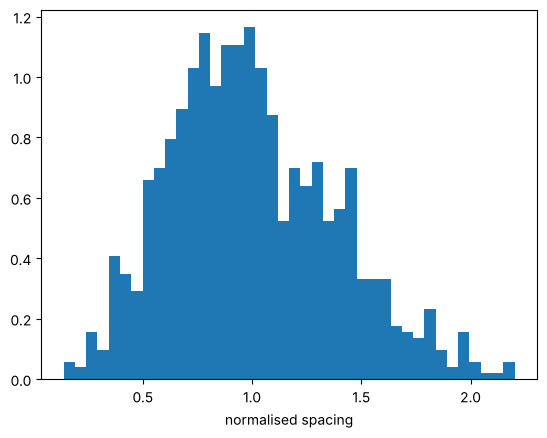

Lehmer's pair: 7005.06286617 7005.10056467  gap 0.03770, normalised 0.0421


In [4]:
t0 = time.time()
zs = [float(mp.findroot(mp.siegelz, (grid[i], grid[i + 1]), solver='illinois'))
      for i in np.nonzero(Zs[:-1] * Zs[1:] < 0)[0]]
print('sign changes up to T = g_998 = %.3f: %d   mpmath nzeros(T): %d   (%.0f s)' % (T, len(zs), mp.nzeros(T), time.time() - t0))
print('smallest gap between consecutive zeros: %.4f' % min(np.diff(zs)))
print('first five:', [round(z, 6) for z in zs[:5]])
g = np.array(zs)
sp = np.diff(g) * np.log(g[:-1] / (2 * math.pi)) / (2 * math.pi)
print('mean normalised spacing %.4f, smallest %.4f at gamma = %.3f' % (sp.mean(), sp.min(), g[np.argmin(sp)]))
plt.hist(sp, bins=40, density=True); plt.xlabel('normalised spacing'); plt.show()
z1, z2 = mp.zetazero(6709), mp.zetazero(6710)
d = float(z2.imag - z1.imag)
print("Lehmer's pair:", mp.nstr(z1.imag, 12), mp.nstr(z2.imag, 12), ' gap %.5f, normalised %.4f' % (d, d * math.log(float(z1.imag) / (2 * math.pi)) / (2 * math.pi)))

The count of sign changes agrees with $N(T)$, so the $999$ zeros up to $g_{998}$ are all on the line and simple; the first is $14.134725$. The normalised spacings have mean $1$ and a histogram that vanishes at $0$: zeros repel each other, the theme of Chapter 5. Lehmer's pair near $t=7005.06$ is separated by $0.038$, about $0.04$ of the mean spacing there: $Z$ barely crosses the axis between them. Such pairs are dangerous for computations and interesting for theory: a pair that actually touched would be a double zero, or, nearby, a failure of the hypothesis.

### P4.3
**How to find it.** Add $d$ to every multiple of $d$, for all $d\le N$: $\sum_{d\le N}\frac Nd\approx N\log N$ operations, done with numpy slices.

In [5]:
N = 10**6
sig = np.zeros(N + 1, dtype=np.int64)
for d in range(1, N + 1):
    sig[d::d] += d
n = np.arange(3, N + 1)
Gn = sig[3:] / (n * np.log(np.log(n)))
bad = n[Gn >= EG]
print(len(bad), 'violations, the last one', bad.max())
print(bad.tolist())
m = n > 5040
i = np.argmax(Gn[m])
print('max G on ]5040, 10^6]: %.5f at n = %d   (e^gamma = %.5f)' % (Gn[m][i], n[m][i], EG))

26 violations, the last one 5040
[3, 4, 5, 6, 8, 9, 10, 12, 16, 18, 20, 24, 30, 36, 48, 60, 72, 84, 120, 180, 240, 360, 720, 840, 2520, 5040]
max G on ]5040, 10^6]: 1.75581 at n = 10080   (e^gamma = 1.78107)


The $26$ violations of the chapter, the last one $5040$, and beyond $5040$ the maximum of $G$ up to $10^6$ is $1.7558$ at $10\,080=2\cdot5040$. The values of $G$ never come close to $e^\gamma$ in this range: Robin's inequality has room to spare for small $n$, and the danger, if any, lies far out.

### P4.4
**How to find it.** Cumulative sums give $H_n$; compare in floating point (the margins are large except at $n=1$).

In [6]:
H = np.cumsum(1.0 / np.arange(1, N + 1))
rhs = H + np.exp(H) * np.log(H)
lhs = sig[1:].astype(float)
viol = np.nonzero(lhs > rhs + 1e-9)[0] + 1
eq = np.nonzero(np.abs(lhs - rhs) < 1e-9)[0] + 1
print('violations:', viol.tolist(), ' equality at:', eq.tolist())
rel = (rhs[1:] - lhs[1:]) / lhs[1:]
j = np.argmin(rel)
print('smallest relative margin for n >= 2: %.5f at n = %d' % (rel[j], j + 2))
small = np.argsort(rel)[:8] + 2
print('closest n:', sorted(small.tolist()))

violations: []  equality at: [1]
smallest relative margin for n >= 2: 0.01149 at n = 12


closest n: [12, 24, 60, 120, 360, 840, 2520, 5040]


No violation up to $10^6$, equality only at $n=1$. The tightest cases are $12,24,60,120,360,840,2520,5040$, all highly composite, and the very tightest is $n=12$, with a margin of $1.1\%$: Lagarias's inequality is Robin's in disguise, and it is tightest where $\sigma(n)/n$ is largest for the size of $n$.

### P4.5
**How to find it.** The critical values $\varepsilon_{p,a}=\log_p\frac{\sigma(p^{a+1})}{\sigma(p^a)}-1$, sorted in decreasing order, give the prime by which to multiply at each step. Use high precision for $G$ (we work with $\log N$ only).

first CA numbers: [6, 12, 60, 120, 360, 2520, 5040, 55440, 720720, 1441440, 4324320, 21621600]
142 CA numbers in ]5040, 10^300], max G = 1.77183, all below e^gamma: True
e^gamma - G(last) = 0.00924


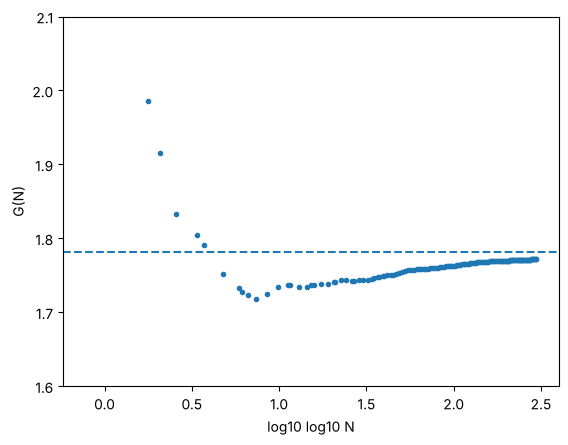

In [7]:
import sympy
mp.mp.dps = 40
crit = []
for p in sympy.primerange(2, 5000):
    for a in range(60):
        e = math.log((p ** (a + 2) - 1) / (p ** (a + 1) - 1)) / math.log(p) - 1
        if e < 1e-7: break
        crit.append((e, p))
crit.sort(reverse=True)
expo, logN, ca = {}, 0.0, []
for e, p in crit:
    expo[p] = expo.get(p, 0) + 1; logN += math.log(p)
    if logN > 300 * math.log(10): break
    r = mp.mpf(1)
    for q, a in expo.items():
        r *= (1 - mp.mpf(q) ** (-a - 1)) / (1 - mp.mpf(1) / q)
    if logN > math.log(3):
        ca.append((logN, float(r / mp.log(logN))))
print('first CA numbers:', [round(math.exp(l)) for l, _ in ca[:12]])
beyond = [(l, Gv) for l, Gv in ca if l > math.log(5040) + 1e-9]
print('%d CA numbers in ]5040, 10^300], max G = %.5f, all below e^gamma: %s' % (len(beyond), max(Gv for _, Gv in beyond), all(Gv < EG for _, Gv in beyond)))
print('e^gamma - G(last) = %.5f' % (EG - ca[-1][1]))
x = [math.log10(l / math.log(10)) for l, _ in ca]
plt.plot(x, [Gv for _, Gv in ca], '.'); plt.axhline(EG, ls='--'); plt.ylim(1.6, 2.1)
plt.xlabel('log10 log10 N'); plt.ylabel('G(N)'); plt.show()

The list starts $6,12,60,120,360,2520,5040,55440,\dots$ (and $2$, left out because $\log\log2<0$). All $142$ colossally abundant numbers between $5040$ and $10^{300}$ satisfy Robin's inequality, and $G(N)$ increases towards $e^\gamma$ very slowly: at $10^{300}$ it is still $0.009$ below. Under the Riemann hypothesis the gap shrinks like a constant over $\sqrt{\log N}$, which explains the slowness.

### P4.6
**How to find it.** $\log n_x=\sum_{p\le x}a_p\log p$ and $\frac{\sigma(n_x)}{n_x}=\prod_{p\le x}\frac{1-p^{-a_p-1}}{1-p^{-1}}$, computed with logarithms.

In [8]:
for e in range(1, 7):
    x = 10**e
    ln = 0.0; ls = 0.0
    for p in sympy.primerange(2, x + 1):
        a = int(2 * math.log(x) / math.log(p))
        while p ** (a + 1) <= x * x: a += 1
        while p ** a > x * x: a -= 1
        ln += a * math.log(p)
        ls += math.log1p(-float(p) ** (-a - 1)) - math.log1p(-1.0 / p)
    print('x = 10^%d   log n_x = %.4g   G(n_x) = %.5f' % (e, ln, math.exp(ls) / math.log(ln)))

x = 10^1   log n_x = 15.66   G(n_x) = 1.55409
x = 10^2   log n_x = 201.1   G(n_x) = 1.56606
x = 10^3   log n_x = 2059   G(n_x) = 1.61875
x = 10^4   log n_x = 2.041e+04   G(n_x) = 1.65507
x = 10^5   log n_x = 2.02e+05   G(n_x) = 1.67909


x = 10^6   log n_x = 2.008e+06   G(n_x) = 1.69556


The values $G(n_x)$ approach $e^\gamma=1.78107$ from below, slowly, because $\log\log n_x=\log x+\log2+o(1)$ while $\frac{\sigma(n_x)}{n_x}\approx e^\gamma\log x$: the ratio is about $e^\gamma\bigl(1-\frac{\log2}{\log x}\bigr)$. The exponents of $n_x$ are too generous; the colossally abundant numbers of P4.5 choose them optimally and do better at every size.